In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("../data/row/subset.csv")
df.head(20)

,id,text,Not Toxic,Hard to Say,Toxic,Very Toxic,category_卑語,category_差別,category_迷惑行為,category_猥褻,category_出会い・プライバシー侵害,category_違法行為,category_偏向表現,annotation_num
0,0,いわゆる天使だろ,2,0,0,1,0,0,0,0,0,0,0,3
1,3,底知れないカリスマ性があるよな,4,0,0,0,0,0,0,0,0,0,0,4
2,9,ありがとう,5,0,0,0,0,0,0,0,0,0,0,5
3,10,地味にこれが一番きつい,3,1,0,0,0,0,0,0,0,0,0,4
4,14,ヤクザより怖い,1,3,0,0,1,3,2,0,0,1,0,4
5,15,それこそ悪魔だわ,3,1,0,0,0,1,0,0,0,0,1,4
6,16,ずるいわ,4,0,0,0,0,0,0,0,0,0,0,4
7,17,こういう明らかに流行るゲームはせめてスタートダッシュかまさないとな,4,0,0,0,0,0,0,0,0,0,0,4
8,27,あっためかえしかよ,3,1,0,0,0,0,0,0,0,0,0,4
9,28,ナイス壁,4,0,0,0,0,0,0,0,0,0,0,4


In [3]:
df.dtypes

id                       int64
text                       str
Not Toxic                int64
Hard to Say              int64
Toxic                    int64
Very Toxic               int64
category_卑語              int64
category_差別              int64
category_迷惑行為            int64
category_猥褻              int64
category_出会い・プライバシー侵害    int64
category_違法行為            int64
category_偏向表現            int64
annotation_num           int64
dtype: object

In [4]:
df.columns.tolist()

['id',
 'text',
 'Not Toxic',
 'Hard to Say',
 'Toxic',
 'Very Toxic',
 'category_卑語',
 'category_差別',
 'category_迷惑行為',
 'category_猥褻',
 'category_出会い・プライバシー侵害',
 'category_違法行為',
 'category_偏向表現',
 'annotation_num']

In [5]:
# 欠損値を確認
print(df.isnull().sum())

# annotation_num と各レベルの投票数が一致するか確認
level_columns = [
    "Not Toxic",
    "Hard to Say",
    "Toxic",
    "Very Toxic"
]

print(
    "投票数の合計とannotation_numが一致しない行数:",
    (df[level_columns].sum(axis=1) != df["annotation_num"]).sum()
)

id                       0
text                     0
Not Toxic                0
Hard to Say              0
Toxic                    0
Very Toxic               0
category_卑語              0
category_差別              0
category_迷惑行為            0
category_猥褻              0
category_出会い・プライバシー侵害    0
category_違法行為            0
category_偏向表現            0
annotation_num           0
dtype: int64
投票数の合計とannotation_numが一致しない行数: 0


In [6]:
# 各レベルの重み
level_weights = {
    "Not Toxic": 0,
    "Hard to Say": 1,
    "Toxic": 2,
    "Very Toxic": 3
}

# 重み付き平均を計算
df["level_score"] = sum(
    df[column] * weight
    for column, weight in level_weights.items()
) / df["annotation_num"]

# 四捨五入して整数に変換
# np.round()ではなく、0.5を切り上げる方法を使用
df["level"] = np.floor(df["level_score"] + 0.5).astype(int)

# 確認
df[["text", "Not Toxic", "Hard to Say",
    "Toxic", "Very Toxic", "annotation_num",
    "level_score", "level"]].head(20)

,text,Not Toxic,Hard to Say,Toxic,Very Toxic,annotation_num,level_score,level
0,いわゆる天使だろ,2,0,0,1,3,1.00,1
1,底知れないカリスマ性があるよな,4,0,0,0,4,0.00,0
2,ありがとう,5,0,0,0,5,0.00,0
3,地味にこれが一番きつい,3,1,0,0,4,0.25,0
4,ヤクザより怖い,1,3,0,0,4,0.75,1
5,それこそ悪魔だわ,3,1,0,0,4,0.25,0
6,ずるいわ,4,0,0,0,4,0.00,0
7,こういう明らかに流行るゲームはせめてスタートダッシュかまさないとな,4,0,0,0,4,0.00,0
8,あっためかえしかよ,3,1,0,0,4,0.25,0
9,ナイス壁,4,0,0,0,4,0.00,0


In [7]:
# カテゴリ列
category_columns = [
    "category_卑語",
    "category_差別",
    "category_迷惑行為",
    "category_猥褻",
    "category_出会い・プライバシー侵害",
    "category_違法行為",
    "category_偏向表現"
]

def determine_category(row):
    # 各カテゴリの投票数
    votes = row[category_columns]

    # 最大投票数
    max_votes = votes.max()

    # すべて0なら該当カテゴリなし
    if pd.isna(max_votes) or max_votes == 0:
        return None

    # 最大投票数のカテゴリをすべて取得
    winners = votes[votes == max_votes].index.tolist()

    # category_ を取り除いて格納
    return "|".join(
        category.replace("category_", "")
        for category in winners
    )

df["category"] = df.apply(determine_category, axis=1)

# 確認
df[["text", "category"]].head(20)

,text,category
0,いわゆる天使だろ,NaN
1,底知れないカリスマ性があるよな,NaN
2,ありがとう,NaN
3,地味にこれが一番きつい,NaN
4,ヤクザより怖い,差別
5,それこそ悪魔だわ,差別|偏向表現
6,ずるいわ,NaN
7,こういう明らかに流行るゲームはせめてスタートダッシュかまさないとな,NaN
8,あっためかえしかよ,NaN
9,ナイス壁,NaN


In [8]:
# いったん欠損値で初期化
df["classification"] = pd.NA

# 自動で決められるレベルを設定
df.loc[df["level"] == 0, "classification"] = 0
df.loc[df["level"].isin([2, 3]), "classification"] = 1

# 整数型を保ち、未設定値を許容
df["classification"] = df["classification"].astype("Int64")

# 確認
print(df.groupby(["level", "classification"], dropna=False).size())

level  classification
0      0                 279
1      <NA>              111
2      1                  38
3      1                   9
dtype: int64


In [9]:
# 手動確認が必要な行
hard_to_say_df = df.loc[
    df["level"] == 1,
    ["id", "text", "level_score", "level", "classification"]
].copy()

display(hard_to_say_df)

,id,text,level_score,level,classification
0,0,いわゆる天使だろ,1.00,1,<NA>
4,14,ヤクザより怖い,0.75,1,<NA>
11,38,この結論を導くために実施された市民投票なんだろ,0.50,1,<NA>
15,48,絶対ムリなのに中国は何なんだ,0.75,1,<NA>
16,53,なんだろみんなお胸がすごいことになってるのに,1.25,1,<NA>
...,...,...,...,...,...
416,960,かなりの曲者だ,0.50,1,<NA>
424,973,ルール守れというだけで発狂するんだし無理でしょ,1.00,1,<NA>
430,984,全く男として見ていない,1.00,1,<NA>
433,989,この衣装カッコいい、可愛いから欲しいってやつ以外もう課金要素ないだろ,1.00,1,<NA>


In [10]:
# 未設定の分類が残っていないか確認
print("classificationの未設定件数:",
      df["classification"].isna().sum())

# 分類ごとの件数
print(df["classification"].value_counts(dropna=False))

classificationの未設定件数: 111
classification
0       279
<NA>    111
1        47
Name: count, dtype: Int64


In [11]:
# 出力先
output_path = "../data/processed/toxic_dataset_1.csv"

# 必要な列を選択
output_columns = [
    "id",
    "text",
    "level_score",
    "level",
    "classification",
    "category",
    "annotation_num"
]

df[output_columns].to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"保存しました: {output_path}")

保存しました: ../data/processed/toxic_dataset_1.csv


# Only Classを読み込んで学習

In [12]:
import pandas as pd

df = pd.read_csv("../data/processed/toxic_dataset_1.csv")
df.head(20)

,id,text,level_score,level,classification,category,annotation_num
0,0,いわゆる天使だろ,1.00,1,NaN,NaN,3
1,3,底知れないカリスマ性があるよな,0.00,0,0.0,NaN,4
2,9,ありがとう,0.00,0,0.0,NaN,5
3,10,地味にこれが一番きつい,0.25,0,0.0,NaN,4
4,14,ヤクザより怖い,0.75,1,NaN,差別,4
5,15,それこそ悪魔だわ,0.25,0,0.0,差別|偏向表現,4
6,16,ずるいわ,0.00,0,0.0,NaN,4
7,17,こういう明らかに流行るゲームはせめてスタートダッシュかまさないとな,0.00,0,0.0,NaN,4
8,27,あっためかえしかよ,0.25,0,0.0,NaN,4
9,28,ナイス壁,0.00,0,0.0,NaN,4


In [13]:
df.dtypes

id                  int64
text                  str
level_score       float64
level               int64
classification    float64
category              str
annotation_num      int64
dtype: object

In [14]:
df["classification"].value_counts()

classification
0.0    279
1.0     47
Name: count, dtype: int64

In [15]:
# classification=1 かつ categoryがNaNの行を抽出
condition = (df["classification"] == 1) & (df["category"].isna())

# 該当件数
print("該当件数:", condition.sum())

# 全データに対する割合（%）
print("全データに対する割合:", round(condition.mean() * 100, 2), "%")

該当件数: 2
全データに対する割合: 0.46 %


In [16]:
# classificationがNaNの行
condition = df["classification"].isna()

# categoryがNaNなら0.0、そうでなければ1.0を設定
df.loc[condition & df["category"].isna(), "classification"] = 0.0
df.loc[condition & df["category"].notna(), "classification"] = 1.0

# classificationの欠損件数
print("classificationのNaN件数:", condition.sum())

# classificationごとの件数
print(df["classification"].value_counts(dropna=False))

# 結果を確認
df.head(20)

classificationのNaN件数: 111
classification
0.0    325
1.0    112
Name: count, dtype: int64


,id,text,level_score,level,classification,category,annotation_num
0,0,いわゆる天使だろ,1.00,1,0.0,NaN,3
1,3,底知れないカリスマ性があるよな,0.00,0,0.0,NaN,4
2,9,ありがとう,0.00,0,0.0,NaN,5
3,10,地味にこれが一番きつい,0.25,0,0.0,NaN,4
4,14,ヤクザより怖い,0.75,1,1.0,差別,4
5,15,それこそ悪魔だわ,0.25,0,0.0,差別|偏向表現,4
6,16,ずるいわ,0.00,0,0.0,NaN,4
7,17,こういう明らかに流行るゲームはせめてスタートダッシュかまさないとな,0.00,0,0.0,NaN,4
8,27,あっためかえしかよ,0.25,0,0.0,NaN,4
9,28,ナイス壁,0.00,0,0.0,NaN,4


In [17]:
df["category"].value_counts()

category
迷惑行為              51
差別                21
偏向表現              12
差別|迷惑行為            6
猥褻                 6
卑語                 5
差別|偏向表現            2
差別|猥褻              2
差別|迷惑行為|偏向表現       2
迷惑行為|偏向表現          2
卑語|迷惑行為            2
違法行為               2
差別|迷惑行為|猥褻         1
出会い・プライバシー侵害       1
迷惑行為|違法行為|偏向表現     1
卑語|猥褻              1
卑語|迷惑行為|猥褻         1
Name: count, dtype: int64

In [18]:
# 分類ラベルとカテゴリの不整合を確認
condition = (
    (df["classification"] == 0) &
    (df["category"].notna())
)

print("除外候補:", condition.sum())

除外候補: 8


In [19]:
# 内容を確認したうえで、今回のタスクに合わない行を除外
df = df.loc[~condition].copy()

# categoryが欠損している投稿を「適切」とする
df["category"] = df["category"].fillna("適切")

# カテゴリごとのデータ件数を確認
print(df["category"].value_counts(dropna=False))

# 割合も確認
print(
    df["category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

category
適切                319
迷惑行為               49
差別                 18
偏向表現               11
差別|迷惑行為             6
猥褻                  6
卑語                  4
差別|猥褻               2
差別|迷惑行為|偏向表現        2
迷惑行為|偏向表現           2
卑語|迷惑行為             2
違法行為                2
差別|迷惑行為|猥褻          1
出会い・プライバシー侵害        1
迷惑行為|違法行為|偏向表現      1
差別|偏向表現             1
卑語|猥褻               1
卑語|迷惑行為|猥褻          1
Name: count, dtype: int64
category
適切                74.36
迷惑行為              11.42
差別                 4.20
偏向表現               2.56
差別|迷惑行為            1.40
猥褻                 1.40
卑語                 0.93
差別|猥褻              0.47
差別|迷惑行為|偏向表現       0.47
迷惑行為|偏向表現          0.47
卑語|迷惑行為            0.47
違法行為               0.47
差別|迷惑行為|猥褻         0.23
出会い・プライバシー侵害       0.23
迷惑行為|違法行為|偏向表現     0.23
差別|偏向表現            0.23
卑語|猥褻              0.23
卑語|迷惑行為|猥褻         0.23
Name: proportion, dtype: float64


In [21]:
# 予測対象となる7種類のカテゴリ
CATEGORIES = [
    "卑語",
    "差別",
    "迷惑行為",
    "猥褻",
    "出会い・プライバシー侵害",
    "違法行為",
    "偏向表現",
]

# category列は補完済みのため、ここではNaN補完を行わない
df["category"] = df["category"].astype(str).str.strip()

# カテゴリの表記を分割し、各カテゴリを0/1に変換
for category in CATEGORIES:
    df[category] = df["category"].apply(
        lambda value: int(category in value.split("|"))
    )

# 変換結果を確認
print("データ件数:", len(df))

print("\nカテゴリごとの該当件数:")
print(df[CATEGORIES].sum().sort_values(ascending=False))

print("\nすべてのカテゴリが0の件数（適切）:")
print((df[CATEGORIES].sum(axis=1) == 0).sum())

# 変換結果を保存
df.to_csv("../data/processed/toxic_dataset_multilabel.csv", index=False, encoding="utf-8-sig")

データ件数: 429

カテゴリごとの該当件数:
迷惑行為            64
差別              30
偏向表現            17
猥褻              11
卑語               8
違法行為             3
出会い・プライバシー侵害     1
dtype: int64

すべてのカテゴリが0の件数（適切）:
319


### 加工後のデータについて

In [67]:
df = pd.read_csv("../data/processed/toxic_dataset_only_category.csv")
df

,text,category
0,いわゆる天使だろ,適切
1,底知れないカリスマ性があるよな,適切
2,ありがとう,適切
3,地味にこれが一番きつい,適切
4,ヤクザより怖い,差別
...,...,...
424,第二の大口病院,適切
425,この衣装カッコいい、可愛いから欲しいってやつ以外もう課金要素ないだろ,迷惑行為
426,そこまで未練なら風俗行きゃいいじゃん,猥褻
427,ボイスはもう少しバリエーション取ってくれ,適切


In [68]:
df["category"].replace("迷惑行為", "誹謗中傷")

0        適切
1        適切
2        適切
3        適切
4        差別
       ... 
424      適切
425    誹謗中傷
426      猥褻
427      適切
428      適切
Name: category, Length: 429, dtype: str

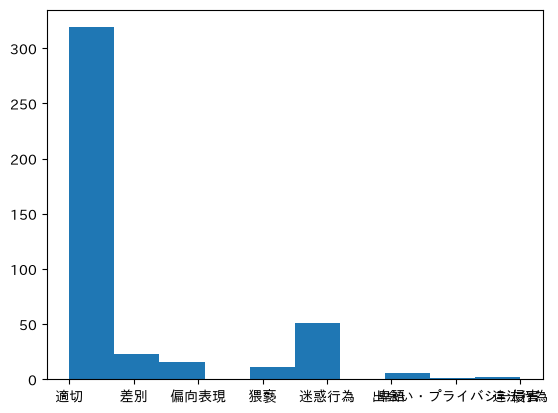

In [72]:
import matplotlib.pyplot as plt
import japanize_matplotlib

plt.hist(df["category"])
plt.show()

In [76]:
df["category"].value_counts()

category
適切              319
迷惑行為             51
差別               23
偏向表現             16
猥褻               11
卑語                6
違法行為              2
出会い・プライバシー侵害      1
Name: count, dtype: int64

## 学習

In [81]:
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/processed/toxic_dataset_only_class.csv")

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["classification"]
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["classification"]
)

print("train:", len(train_df))
print("valid:", len(valid_df))
print("test :", len(test_df))

train: 349
valid: 44
test : 44


In [82]:
from datasets import Dataset

train_dataset = Dataset.from_pandas(
    train_df[["text", "classification"]]
)

valid_dataset = Dataset.from_pandas(
    valid_df[["text", "classification"]]
)

test_dataset = Dataset.from_pandas(
    test_df[["text", "classification"]]
)

print("="*80)
print(train_dataset)
print(train_dataset[0])
print("="*80)
print(valid_dataset)
print(valid_dataset[0])
print("="*80)
print(test_dataset)
print(test_dataset[0])

Dataset({
    features: ['text', 'classification', '__index_level_0__'],
    num_rows: 349
})
{'text': 'まだ撮影してないっぽいよね', 'classification': 0, '__index_level_0__': 251}
Dataset({
    features: ['text', 'classification', '__index_level_0__'],
    num_rows: 44
})
{'text': 'お爺さんかわいそう', 'classification': 1, '__index_level_0__': 65}
Dataset({
    features: ['text', 'classification', '__index_level_0__'],
    num_rows: 44
})
{'text': '大丈夫じゃない', 'classification': 0, '__index_level_0__': 314}


In [83]:
from transformers import AutoTokenizer

MODEL_NAME = "cl-tohoku/bert-base-japanese-v3"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [84]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [85]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_valid = valid_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

print(tokenized_train[0])
print(tokenized_valid[0])
print(tokenized_test[0])

Map: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 44/44 [00:00<00:00, 4265.26 examples/s]

{'text': 'まだ撮影してないっぽいよね', 'classification': 0, '__index_level_0__': 251, 'input_ids': [2, 14464, 13265, 441, 456, 12494, 23273, 490, 463, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}
{'text': 'お爺さんかわいそう', 'classification': 1, '__index_level_0__': 65, 'input_ids': [2, 428, 3695, 1303

In [86]:
text = train_dataset[0]["text"]

print("元の文章:")
print(text)

print("\nトークン:")
print(tokenizer.tokenize(text))

print("\nID:")
print(tokenizer.convert_tokens_to_ids(tokenizer.tokenize(text)))

print("\nTokenizerの出力:")
print(tokenizer(
    text,
    padding="max_length",
    truncation=True,
    max_length=128
))

元の文章:
まだ撮影してないっぽいよね

トークン:
['まだ', '撮影', 'し', 'て', 'ない', 'っぽい', 'よ', 'ね']

ID:
[14464, 13265, 441, 456, 12494, 23273, 490, 463]

Tokenizerの出力:
{'input_ids': [2, 14464, 13265, 441, 456, 12494, 23273, 490, 463, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


## BERTでの学習

In [87]:
from transformers import AutoModelForSequenceClassification

In [88]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 14044.77it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: cl-tohoku/bert-base-japanese-v3
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                        

In [89]:
def rename_label(dataset):
    return dataset.rename_column(
        "classification",
        "labels"
    )

tokenized_train = rename_label(tokenized_train)
tokenized_valid = rename_label(tokenized_valid)
tokenized_test = rename_label(tokenized_test)

In [90]:
print(tokenized_train[0])

{'text': 'まだ撮影してないっぽいよね', 'labels': 0, '__index_level_0__': 251, 'input_ids': [2, 14464, 13265, 441, 456, 12494, 23273, 490, 463, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


In [91]:
from transformers import TrainingArguments
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import Trainer

### 重み付け無しの場合

In [92]:
training_args = TrainingArguments(
    output_dir="./models/toxic-bert",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    # logging_dir="./logs",
    logging_steps=50,
    load_best_model_at_end=True
)

training_args_1 = TrainingArguments(
    output_dir="./models/toxic-bert-tuned",
    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=1e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    num_train_epochs=5,
    weight_decay=0.01,

    logging_steps=10,
    load_best_model_at_end=True,

    metric_for_best_model="eval_f1",
    greater_is_better=True
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary"
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [93]:
trainer = Trainer(
    model=model,
    args=training_args_1,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_valid,
    compute_metrics=compute_metrics
)

trainer.train()

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.646625,0.588355,0.727273,0.000000,0.000000,0.000000
2,0.535016,0.539830,0.727273,0.000000,0.000000,0.000000
3,0.473225,0.536381,0.750000,0.666667,0.166667,0.266667
4,0.333493,0.521245,0.750000,0.666667,0.166667,0.266667
5,0.279427,0.518640,0.772727,0.750000,0.250000,0.375000


/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.13s/it]
/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control 

TrainOutput(global_step=220, training_loss=0.44541055939414287, metrics={'train_runtime': 897.6834, 'train_samples_per_second': 1.944, 'train_steps_per_second': 0.245, 'total_flos': 114782197900800.0, 'train_loss': 0.44541055939414287, 'epoch': 5.0})

In [94]:
test_result = trainer.evaluate(
    tokenized_test
)

print(test_result)

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.279427,0.428346,5,0.704545,0.250000,0.090909,0.133333


{'eval_loss': 0.4283464550971985, 'eval_accuracy': 0.7045454545454546, 'eval_precision': 0.25, 'eval_recall': 0.09090909090909091, 'eval_f1': 0.13333333333333333}


In [95]:
print("=== train ===")
print(train_df["classification"].value_counts())

print("\n=== validation ===")
print(valid_df["classification"].value_counts())

print("\n=== test ===")
print(test_df["classification"].value_counts())

=== train ===
classification
0    260
1     89
Name: count, dtype: int64

=== validation ===
classification
0    32
1    12
Name: count, dtype: int64

=== test ===
classification
0    33
1    11
Name: count, dtype: int64


In [96]:
from sklearn.metrics import confusion_matrix

predictions = trainer.predict(tokenized_valid)

pred_labels = np.argmax(
    predictions.predictions,
    axis=-1
)

true_labels = predictions.label_ids

print(confusion_matrix(true_labels, pred_labels))

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[[31  1]
 [ 9  3]]


### クラス重みづけを追加

In [97]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["classification"].astype(int)
)

print(class_weights)

[0.67115385 1.96067416]


In [98]:
import torch
from transformers import Trainer

class WeightedTrainer(Trainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        weights = torch.tensor(
            class_weights,
            dtype=torch.float32,
            device=logits.device
        )

        loss_function = torch.nn.CrossEntropyLoss(
            weight=weights
        )

        loss = loss_function(logits, labels)

        return (loss, outputs) if return_outputs else loss

In [99]:
training_args = TrainingArguments(
    output_dir="./models/toxic-bert-weighted",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=5,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_valid,
    compute_metrics=compute_metrics
)

trainer.train()

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.281422,0.768926,0.795455,0.666667,0.500000,0.571429
2,0.223731,0.856917,0.750000,0.545455,0.500000,0.521739
3,0.072493,1.133091,0.750000,0.555556,0.416667,0.476190
4,0.021988,1.389599,0.818182,0.833333,0.416667,0.555556
5,0.019590,1.330062,0.750000,0.555556,0.416667,0.476190


Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.20it/s]
/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.25it/s]
/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.51it/s]
/home/kobat/bbs-with-AI-moni

TrainOutput(global_step=220, training_loss=0.12540243159640918, metrics={'train_runtime': 898.9884, 'train_samples_per_second': 1.941, 'train_steps_per_second': 0.245, 'total_flos': 114782197900800.0, 'train_loss': 0.12540243159640918, 'epoch': 5.0})

In [101]:
test_result = trainer.evaluate(
    tokenized_test
)

print(test_result)

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.019590,0.529113,5,0.818182,0.714286,0.454545,0.555556


{'eval_loss': 0.529113233089447, 'eval_accuracy': 0.8181818181818182, 'eval_precision': 0.7142857142857143, 'eval_recall': 0.45454545454545453, 'eval_f1': 0.5555555555555556}


In [102]:
from sklearn.metrics import confusion_matrix

predictions = trainer.predict(tokenized_valid)

pred_labels = np.argmax(
    predictions.predictions,
    axis=-1
)

true_labels = predictions.label_ids

print(confusion_matrix(true_labels, pred_labels))

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[[29  3]
 [ 6  6]]


エポック数を少なくした場合

In [105]:
training_args_1 = TrainingArguments(
    output_dir="./models/toxic-bert-weighted",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True
)

trainer = WeightedTrainer(
    model=model,
    args=training_args_1,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_valid,
    compute_metrics=compute_metrics
)

trainer.train()

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.182656,1.107983,0.772727,0.666667,0.333333,0.444444
2,0.153232,1.066109,0.750000,0.538462,0.583333,0.560000


Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.27it/s]
/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.16it/s]


TrainOutput(global_step=88, training_loss=0.10221547023816542, metrics={'train_runtime': 313.1776, 'train_samples_per_second': 2.229, 'train_steps_per_second': 0.281, 'total_flos': 45912879160320.0, 'train_loss': 0.10221547023816542, 'epoch': 2.0})

In [106]:
test_result = trainer.evaluate(
    tokenized_test
)

print(test_result)

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.153232,0.746211,2,0.795455,0.666667,0.363636,0.470588


{'eval_loss': 0.746211051940918, 'eval_accuracy': 0.7954545454545454, 'eval_precision': 0.6666666666666666, 'eval_recall': 0.36363636363636365, 'eval_f1': 0.47058823529411764}


In [107]:
from sklearn.metrics import confusion_matrix

predictions = trainer.predict(tokenized_valid)

pred_labels = np.argmax(
    predictions.predictions,
    axis=-1
)

true_labels = predictions.label_ids

print(confusion_matrix(true_labels, pred_labels))

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[[26  6]
 [ 5  7]]


In [108]:

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 検証データで予測する（テストデータは使わない）
predictions = trainer.predict(tokenized_valid)
logits = predictions.predictions
true_labels = predictions.label_ids

# クラス1（不適切）の予測確率を計算
probabilities = torch.softmax(
    torch.tensor(logits),
    dim=1
).numpy()[:, 1]

# 複数の閾値を比較
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_labels = (
        probabilities >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Confusion matrix:")
    print(confusion_matrix(
        true_labels, pred_labels, labels=[0, 1]
    ))
    print(f"Accuracy : {accuracy_score(true_labels, pred_labels):.3f}")
    print(f"Precision: {precision_score(true_labels, pred_labels, zero_division=0):.3f}")
    print(f"Recall   : {recall_score(true_labels, pred_labels, zero_division=0):.3f}")
    print(f"F1       : {f1_score(true_labels, pred_labels, zero_division=0):.3f}")

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Threshold: 0.3
Confusion matrix:
[[26  6]
 [ 5  7]]
Accuracy : 0.750
Precision: 0.538
Recall   : 0.583
F1       : 0.560

Threshold: 0.4
Confusion matrix:
[[26  6]
 [ 5  7]]
Accuracy : 0.750
Precision: 0.538
Recall   : 0.583
F1       : 0.560

Threshold: 0.5
Confusion matrix:
[[26  6]
 [ 5  7]]
Accuracy : 0.750
Precision: 0.538
Recall   : 0.583
F1       : 0.560

Threshold: 0.6
Confusion matrix:
[[26  6]
 [ 7  5]]
Accuracy : 0.705
Precision: 0.455
Recall   : 0.417
F1       : 0.435

Threshold: 0.7
Confusion matrix:
[[28  4]
 [ 7  5]]
Accuracy : 0.750
Precision: 0.556
Recall   : 0.417
F1       : 0.476


In [109]:
# 検証データの予測確率と正解ラベルを確認
for i, (prob, label) in enumerate(
    zip(probabilities, true_labels)
):
    print(
        f"Index={i}, "
        f"正解={label}, "
        f"不適切確率={prob:.4f}"
    )

Index=0, 正解=1, 不適切確率=0.2577
Index=1, 正解=0, 不適切確率=0.9655
Index=2, 正解=1, 不適切確率=0.8242
Index=3, 正解=0, 不適切確率=0.0349
Index=4, 正解=0, 不適切確率=0.0040
Index=5, 正解=0, 不適切確率=0.0179
Index=6, 正解=0, 不適切確率=0.1529
Index=7, 正解=0, 不適切確率=0.7151
Index=8, 正解=1, 不適切確率=0.0034
Index=9, 正解=0, 不適切確率=0.6891
Index=10, 正解=0, 不適切確率=0.0045
Index=11, 正解=1, 不適切確率=0.9612
Index=12, 正解=1, 不適切確率=0.9933
Index=13, 正解=1, 不適切確率=0.1620
Index=14, 正解=0, 不適切確率=0.0074
Index=15, 正解=0, 不適切確率=0.0040
Index=16, 正解=0, 不適切確率=0.0057
Index=17, 正解=0, 不適切確率=0.0743
Index=18, 正解=1, 不適切確率=0.5893
Index=19, 正解=0, 不適切確率=0.0274
Index=20, 正解=1, 不適切確率=0.0101
Index=21, 正解=0, 不適切確率=0.9899
Index=22, 正解=0, 不適切確率=0.8566
Index=23, 正解=0, 不適切確率=0.0623
Index=24, 正解=0, 不適切確率=0.0032
Index=25, 正解=1, 不適切確率=0.9179
Index=26, 正解=0, 不適切確率=0.0067
Index=27, 正解=0, 不適切確率=0.0052
Index=28, 正解=0, 不適切確率=0.0628
Index=29, 正解=1, 不適切確率=0.0034
Index=30, 正解=0, 不適切確率=0.0242
Index=31, 正解=0, 不適切確率=0.0617
Index=32, 正解=0, 不適切確率=0.0533
Index=33, 正解=0, 不適切確率=0.0124
Index=34, 正解=0, 不適切確率=0.

# モデルの保存

In [110]:
from pathlib import Path

MODEL_DIR = Path("./models/toxic-bert")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 学習済みモデルとトークナイザーを保存
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

print(f"モデルを保存しました: {MODEL_DIR.resolve()}")

Writing model shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:03<00:00,  3.44s/it]


モデルを保存しました: /home/kobat/bbs-with-AI-monitoring/analysis/models/toxic-bert
